# Marketplace analytics: what drives repeat purchases and 5-star reviews
Real data: Olist public e-commerce dataset (Brazil, 2016-2018, CC BY-NC-SA 4.0).

This notebook does everything SQL is not good at: statistical tests, a logistic regression, the RFM summary and a
validated forecast. Every number shown in the Power BI report comes either from a query in `sql/` or from a cell
below, and is exported to `data/output/`.

Run `python src/prepare_data.py` and `python src/run_sql.py` first.

In [1]:
import pathlib
import numpy as np
import pandas as pd
import duckdb
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
CLEAN, OUT = ROOT / "data" / "clean", ROOT / "data" / "output"

con = duckdb.connect()
for f in sorted(CLEAN.glob("*.parquet")):
    con.execute(f"CREATE VIEW {f.stem} AS SELECT * FROM read_parquet('{f.as_posix()}')")
q = lambda sql: con.execute(sql).df()

rng = np.random.default_rng(42)
pd.set_option("display.width", 160)

# Every headline number of the report is stored here, then exported to data/output/kpis.csv
KPI = {}
def kpi(key, value, label):
    KPI[key] = (value, label)
    return value

## 1 · Growth & retention
Valid orders only: cancelled and unavailable orders (1,234) and orders without items are excluded from GMV.
GMV = item price + freight, taken from `order_items`. Trends use the 19 full months Jan 2017 - Jul 2018
(Sept-Dec 2016 is almost empty and data collection tapers off from 22 Aug 2018).

In [2]:
monthly = pd.read_csv(OUT / "01_monthly_growth.csv", parse_dates=["month"])
cust = q("""SELECT customer_unique_id, COUNT(*) AS orders, MIN(purchase_date) AS first_purchase_date
             FROM orders WHERE is_valid AND in_window GROUP BY 1""")
ytd17 = monthly[(monthly.month.dt.year == 2017) & (monthly.month.dt.month <= 7)]
ytd18 = monthly[(monthly.month.dt.year == 2018) & (monthly.month.dt.month <= 7)]

kpi("valid_orders", int(monthly.orders.sum()), "Valid orders, Jan 2017 - Jul 2018")
kpi("gmv_total", round(monthly.gmv.sum()), "GMV (BRL), Jan 2017 - Jul 2018")
kpi("gmv_growth_ytd", round(ytd18.gmv.sum() / ytd17.gmv.sum() - 1, 4), "GMV growth Jan-Jul 2018 vs Jan-Jul 2017")
kpi("orders_growth_ytd", round(ytd18.orders.sum() / ytd17.orders.sum() - 1, 4), "Orders growth Jan-Jul 2018 vs Jan-Jul 2017")
kpi("customers", len(cust), "Real customers (customer_unique_id) with a valid order")
kpi("repeat_rate", round((cust.orders >= 2).mean(), 4), "Share of customers with 2+ valid orders, Jan 2017 - Jul 2018")
kpi("new_customer_order_share", round(1 - monthly.repeat_orders.sum() / monthly.orders.sum(), 4),
    "Share of orders that are a customer's first order")
for k in ["valid_orders", "gmv_total", "gmv_growth_ytd", "orders_growth_ytd", "customers", "repeat_rate", "new_customer_order_share"]:
    print(f"{KPI[k][1]:<60} {KPI[k][0]}")

Valid orders, Jan 2017 - Jul 2018                            91484
GMV (BRL), Jan 2017 - Jul 2018                               14686733
GMV growth Jan-Jul 2018 vs Jan-Jul 2017                      1.6076
Orders growth Jan-Jul 2018 vs Jan-Jul 2017                   1.5757
Real customers (customer_unique_id) with a valid order       88494
Share of customers with 2+ valid orders, Jan 2017 - Jul 2018 0.0304
Share of orders that are a customer's first order            0.9672


Why `customer_unique_id`: Olist creates a new `customer_id` for every order, so counting `customer_id` would show
99,441 "customers" and a repeat rate of exactly 0%. `customer_unique_id` is the person.

In [3]:
print("orders per customer_unique_id:")
print(cust.orders.value_counts().sort_index().to_string())

orders per customer_unique_id:
orders
1     85804
2      2472
3       176
4        24
5         9
6         4
7         3
9         1
13        1


Cohort retention (from `sql/02_cohort_retention.sql`, censoring-safe): average share of a cohort that orders again
in month 1, 3 and 6 after its first purchase, weighted by cohort size.

month  1: 0.48%  (18 cohorts observed)
month  3: 0.26%  (16 cohorts observed)
month  6: 0.23%  (13 cohorts observed)
month 12: 0.19%  (7 cohorts observed)


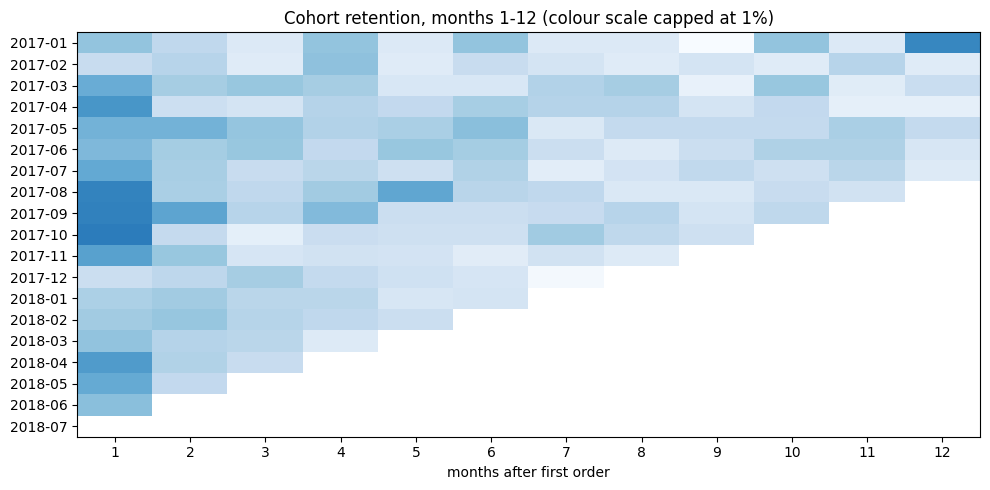

In [4]:
coh = pd.read_csv(OUT / "02_cohort_retention.csv", parse_dates=["cohort_month"])
def weighted_retention(n):
    c = coh[coh.month_n == n]
    return c.active_customers.sum() / c.customers.sum()
for n in [1, 3, 6, 12]:
    print(f"month {n:>2}: {weighted_retention(n):.2%}  ({(coh.month_n == n).sum()} cohorts observed)")
kpi("retention_m1", round(weighted_retention(1), 4), "Average month-1 retention (weighted by cohort size)")

pivot = coh.pivot(index="cohort_month", columns="month_n", values="retention")
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(pivot.iloc[:, 1:13].values, cmap="Blues", aspect="auto", vmin=0, vmax=0.01)
ax.set_yticks(range(len(pivot)), pivot.index.strftime("%Y-%m"))
ax.set_xticks(range(12), range(1, 13))
ax.set_xlabel("months after first order"); ax.set_title("Cohort retention, months 1-12 (colour scale capped at 1%)")
plt.tight_layout(); plt.show()

## 2 · Delivery & satisfaction
Delay = actual delivery date − promised date. "Late" = delivered after the promised date.
Population: delivered orders in the window with a delivery date and a review.

In [5]:
d = q("""
    SELECT order_id, delay_days, review_score, delay_days > 0 AS is_late
    FROM orders
    WHERE is_valid AND in_window AND order_status = 'delivered'
      AND delivered_date IS NOT NULL AND review_score IS NOT NULL
""")
late, ontime = d.loc[d.is_late, "review_score"].to_numpy(), d.loc[~d.is_late, "review_score"].to_numpy()
print(f"orders: {len(d):,}  late: {len(late):,} ({len(late)/len(d):.1%})")
print(f"mean review  on time {ontime.mean():.2f}  late {late.mean():.2f}")
print(f"1-2 stars    on time {(ontime <= 2).mean():.1%}  late {(late <= 2).mean():.1%}")

# Review scores are 1-5 ordinal values, not normally distributed -> Mann-Whitney U (compares the whole distribution)
u = stats.mannwhitneyu(ontime, late, alternative="two-sided")
print(f"Mann-Whitney U = {u.statistic:,.0f}, p = {u.pvalue:.1e}")
print(f"P(random on-time order rated higher than random late order, ties count half) = {u.statistic / (len(ontime) * len(late)):.2f}")

orders: 89,230  late: 5,993 (6.7%)
mean review  on time 4.28  late 2.22
1-2 stars    on time 9.4%  late 63.7%
Mann-Whitney U = 411,386,812, p = 0.0e+00
P(random on-time order rated higher than random late order, ties count half) = 0.82


Bootstrap: resample both groups 2,000 times to get a 95% confidence interval on the gaps (no distribution assumption).

In [6]:
B = 2000
boot_mean, boot_low = np.empty(B), np.empty(B)
for b in range(B):
    o, l = rng.choice(ontime, len(ontime)), rng.choice(late, len(late))
    boot_mean[b] = o.mean() - l.mean()
    boot_low[b] = (l <= 2).mean() - (o <= 2).mean()
delivery_stats = pd.DataFrame([
    {"metric": "Average review (stars)", "on_time": ontime.mean(), "late": late.mean(),
     "gap": ontime.mean() - late.mean(), "ci_low": np.percentile(boot_mean, 2.5), "ci_high": np.percentile(boot_mean, 97.5),
     "p_value": u.pvalue},
    {"metric": "Share of 1-2 star reviews", "on_time": (ontime <= 2).mean(), "late": (late <= 2).mean(),
     "gap": (late <= 2).mean() - (ontime <= 2).mean(), "ci_low": np.percentile(boot_low, 2.5), "ci_high": np.percentile(boot_low, 97.5),
     "p_value": stats.chi2_contingency(pd.crosstab(d.is_late, d.review_score <= 2))[1]},
])
delivery_stats["orders_on_time"], delivery_stats["orders_late"] = len(ontime), len(late)
# display columns for the report table (stars vs percentages, p-values below 0.001)
star, pct = "{:.2f}".format, "{:.1%}".format
for i, f in enumerate([star, pct]):
    for c in ["on_time", "late", "gap"]:
        delivery_stats.loc[i, c + "_txt"] = f(delivery_stats.loc[i, c])
    delivery_stats.loc[i, "ci_txt"] = f"{f(delivery_stats.loc[i, 'ci_low'])} to {f(delivery_stats.loc[i, 'ci_high'])}"
delivery_stats["p_txt"] = delivery_stats.p_value.map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}")
print(delivery_stats.round(4).to_string(index=False))
delivery_stats.round(5).to_csv(OUT / "delivery_stats.csv", index=False)

kpi("late_share", round(len(late) / len(d), 4), "Share of delivered orders arriving after the promised date")
kpi("review_on_time", round(ontime.mean(), 2), "Average review, on-time orders")
kpi("review_late", round(late.mean(), 2), "Average review, late orders")
kpi("low_on_time", round((ontime <= 2).mean(), 4), "Share of 1-2 star reviews, on-time orders")
kpi("low_late", round((late <= 2).mean(), 4), "Share of 1-2 star reviews, late orders")

                   metric  on_time   late    gap  ci_low  ci_high  p_value  orders_on_time  orders_late on_time_txt late_txt gap_txt         ci_txt   p_txt
   Average review (stars)   4.2837 2.2241 2.0596  2.0186   2.1000      0.0           83237         5993        4.28     2.22    2.06   2.02 to 2.10 < 0.001
Share of 1-2 star reviews   0.0938 0.6369 0.5431  0.5306   0.5552      0.0           83237         5993        9.4%    63.7%   54.3% 53.1% to 55.5% < 0.001


np.float64(0.6369)

Does a late first order reduce the chance of a second one? Customers whose first (delivered) order was placed
before 1 February 2018, so everyone has at least 6 months of follow-up (no censoring). Repurchase = another valid
order on a later day within 180 days (same-day orders are often one basket split by seller).

In [7]:
first = q("""
WITH f AS (
    SELECT o.*, (SELECT arg_max(p.category, i.gmv) FROM order_items i JOIN products p USING (product_id)
                 WHERE i.order_id = o.order_id) AS category
    FROM orders o
    WHERE is_valid AND order_seq = 1 AND order_status = 'delivered' AND delivered_date IS NOT NULL
      AND purchase_date >= DATE '2017-01-01' AND purchase_date < DATE '2018-02-01'
), nxt AS (
    SELECT f.customer_unique_id, MIN(o.purchase_date) AS next_date
    FROM f JOIN orders o ON o.customer_unique_id = f.customer_unique_id AND o.is_valid
                   AND o.purchase_date > f.purchase_date AND o.purchase_date < DATE '2018-08-01'
    GROUP BY 1
)
SELECT f.customer_unique_id, f.delay_days > 0 AS late, f.review_score, f.gmv, f.items, f.category,
       f.customer_state = 'SP' AS sao_paulo,
       COALESCE(n.next_date <= f.purchase_date + INTERVAL 180 DAY, FALSE) AS repurchase
FROM f LEFT JOIN nxt n USING (customer_unique_id)
""")
first["late"], first["repurchase"], first["sao_paulo"] = (first[c].astype(int) for c in ["late", "repurchase", "sao_paulo"])
first["log_gmv"] = np.log(first.gmv)
print(f"customers: {len(first):,}   repurchase within 180 days: {first.repurchase.mean():.2%}")
print(first.groupby("late").repurchase.agg(["count", "mean"]).rename(index={0: "on time", 1: "late"}))

m1 = smf.logit("repurchase ~ late + log_gmv + sao_paulo", data=first).fit(disp=False)
m2 = smf.logit("repurchase ~ late + review_score + log_gmv + sao_paulo", data=first.dropna(subset=["review_score"])).fit(disp=False)
def odds_table(m, name):
    t = pd.DataFrame({"odds_ratio": np.exp(m.params), "ci_low": np.exp(m.conf_int()[0]),
                      "ci_high": np.exp(m.conf_int()[1]), "p_value": m.pvalues})
    t.insert(0, "model", name)
    return t.drop(index="Intercept").rename_axis("variable").reset_index()
logit = pd.concat([odds_table(m1, "A: late + controls"), odds_table(m2, "B: A + review score")])
logit["variable"] = logit.variable.map({"late": "Late first order", "log_gmv": "Order value (log)",
                                        "sao_paulo": "Lives in São Paulo state", "review_score": "Review score (+1 star)"})
logit["ci_txt"] = logit.ci_low.map("{:.2f}".format) + " to " + logit.ci_high.map("{:.2f}".format)
logit["p_txt"] = logit.p_value.map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}")
print(logit.round(4).to_string(index=False))
logit.round(5).to_csv(OUT / "repurchase_logit.csv", index=False)
kpi("repurchase_180d", round(first.repurchase.mean(), 4), "Repurchase within 180 days of first order (first orders Jan 2017 - Jan 2018)")
kpi("late_odds_ratio", round(float(np.exp(m1.params["late"])), 3), "Odds ratio of repurchase, late vs on-time first order")
kpi("review_gap_ci_low", round(float(delivery_stats.loc[0, "ci_low"]), 2), "Bootstrap 95% CI of the review gap, low")
kpi("review_gap_ci_high", round(float(delivery_stats.loc[0, "ci_high"]), 2), "Bootstrap 95% CI of the review gap, high")
kpi("late_odds_p", round(float(m1.pvalues["late"]), 4), "p-value of the late first-order effect on repurchase")

customers: 48,940   repurchase within 180 days: 2.01%
         count      mean
late                    
on time  46163  0.020298
late      2777  0.016565


                variable               model  odds_ratio  ci_low  ci_high  p_value       ci_txt p_txt
        Late first order  A: late + controls      0.8356  0.6195   1.1272   0.2396 0.62 to 1.13 0.240
       Order value (log)  A: late + controls      0.9859  0.9109   1.0672   0.7259 0.91 to 1.07 0.726
Lives in São Paulo state  A: late + controls      1.1921  1.0487   1.3553   0.0072 1.05 to 1.36 0.007
        Late first order B: A + review score      0.9651  0.7019   1.3271   0.8270 0.70 to 1.33 0.827
  Review score (+1 star) B: A + review score      1.0627  1.0040   1.1248   0.0360 1.00 to 1.12 0.036
       Order value (log) B: A + review score      0.9912  0.9155   1.0731   0.8270 0.92 to 1.07 0.827
Lives in São Paulo state B: A + review score      1.1848  1.0418   1.3474   0.0098 1.04 to 1.35 0.010


0.2396

Reading: an odds ratio below 1 means fewer repurchases after a late first order. Here it is 0.84, but its 95%
interval includes 1 (p ≈ 0.24): with only ~2% of customers coming back, the data cannot tell a small effect from
no effect. The honest conclusion is "not detectable", not "no effect".

Even if it were significant, it would be a **correlation**, not a proof of cause: late orders also differ in region,
product size and seller, and the model only controls for order value and São Paulo vs elsewhere. Living in São Paulo
(fast, cheap delivery) is the one clear predictor of coming back (odds x1.19).

## 3 · Sellers

In [8]:
s = pd.read_csv(OUT / "04_seller_scorecard.csv")
n80 = int((s.cum_gmv_share < 0.80).sum() + 1)
kpi("sellers_active", len(s), "Sellers with GMV in the window")
kpi("sellers_80_share", round(n80 / len(s), 4), "Share of sellers making 80% of GMV")
kpi("top10_gmv_share", round(s.loc[s.gmv_rank <= 0.10 * len(s), "gmv"].sum() / s.gmv.sum(), 4), "GMV share of the top 10% sellers")
print(f"{n80} sellers ({n80/len(s):.1%}) make 80% of GMV; top 10% make {KPI['top10_gmv_share'][0]:.1%}")

quad = (s.assign(late_orders=s.late_rate * s.orders)
          .groupby("quadrant")
          .agg(sellers=("seller_id", "count"), gmv=("gmv", "sum"), orders=("orders", "sum"),
               avg_review=("avg_review", "mean"), late_rate=("late_rate", "mean"))
          .assign(gmv_share=lambda x: x.gmv / x.gmv.sum()).reset_index())
print(quad.round(3).to_string(index=False))
quad.round(5).to_csv(OUT / "seller_quadrants.csv", index=False)
fix = s[s.quadrant.str.startswith("Big & poor")]
kpi("fix_sellers", len(fix), "Big sellers (top 10% GMV) with average review below 3.8")
kpi("fix_gmv_share", round(fix.gmv.sum() / s.gmv.sum(), 4), "GMV share of those sellers")
print(fix[["seller_id", "state", "orders", "gmv", "late_rate", "avg_review", "share_1_2_stars"]].round(3).head(15).to_string(index=False))

528 sellers (18.3%) make 80% of GMV; top 10% make 66.5%
                        quadrant  sellers        gmv  orders  avg_review  late_rate  gmv_share
    Big & poor rating: fix first       32  925930.47    5485       3.525      0.104      0.063
       Big & well rated: protect      255 8843338.59   52125       4.123      0.068      0.602
    Small & poor rating: monitor       45  260161.02    2508       3.566      0.125      0.018
Small, well rated or < 30 orders     2546 4657303.15   32587       4.047      0.069      0.317
                       seller_id state  orders       gmv  late_rate  avg_review  share_1_2_stars
7c67e1448b00f6e969d365cea6b010ab    SP     973 237791.99      0.091       3.482            0.258
712e6ed8aa4aa1fa65dab41fed5737e4    SC      79  46704.13      0.208       3.385            0.346
2eb70248d66e0e3ef83659f71b244378    SP     202  45860.10      0.112       2.697            0.500
855668e0971d4dfd7bef1b6a4133b41b    SP     307  39459.84      0.128       3.781  

Are poor ratings at these sellers driven by lateness? Compare late rates and the score of their on-time orders.

In [9]:
seller_orders = q("""
    SELECT DISTINCT i.seller_id, o.order_id, o.delay_days > 0 AS is_late, o.review_score
    FROM order_items i JOIN orders o USING (order_id)
    WHERE o.is_valid AND o.in_window AND o.order_status = 'delivered' AND o.delivered_date IS NOT NULL AND o.review_score IS NOT NULL
""").merge(s[["seller_id", "quadrant"]], on="seller_id")
print(seller_orders.groupby(["quadrant", "is_late"]).review_score.agg(["count", "mean"]).round(2))

                                          count  mean
quadrant                         is_late             
Big & poor rating: fix first     False     4810  3.76
                                 True       512  2.00
Big & well rated: protect        False    47690  4.29
                                 True      3339  2.26
Small & poor rating: monitor     False     2120  3.84
                                 True       283  1.84
Small, well rated or < 30 orders False    29810  4.33
                                 True      1871  2.29


## 4 · Customers & basket — RFM
Snapshot date 1 Aug 2018. With ~97% one-time buyers, Frequency barely separates customers, so segments rest on
Recency and Monetary quintiles, plus a separate "repeat buyers" group.

In [10]:
rfm = pd.read_csv(OUT / "05_rfm.csv")
seg = (rfm.groupby("segment")
          .agg(customers=("customer_unique_id", "count"), gmv=("monetary", "sum"),
               avg_spend=("monetary", "mean"), avg_recency_days=("recency_days", "mean"))
          .assign(customer_share=lambda x: x.customers / x.customers.sum(), gmv_share=lambda x: x.gmv / x.gmv.sum())
          .reset_index())
print(seg.round(3).to_string(index=False))

cat_seg = q("""
    SELECT c.customer_unique_id, p.category, SUM(i.gmv) AS gmv
    FROM orders o JOIN order_items i USING (order_id) JOIN products p USING (product_id)
    JOIN customers c USING (customer_unique_id)
    WHERE o.is_valid AND o.purchase_date < DATE '2018-08-01'
    GROUP BY 1, 2
""").merge(rfm[["customer_unique_id", "segment"]], on="customer_unique_id")
top_cat = (cat_seg.groupby(["segment", "category"]).gmv.sum().reset_index()
                  .assign(share=lambda x: x.gmv / x.groupby("segment").gmv.transform("sum"))
                  .sort_values(["segment", "gmv"], ascending=[True, False]).groupby("segment").head(3))
seg["top_categories"] = seg.segment.map(top_cat.groupby("segment").category.apply(lambda c: ", ".join(c.str.replace("_", " "))))
print(seg[["segment", "top_categories"]].to_string(index=False))
seg.round(5).to_csv(OUT / "rfm_segments.csv", index=False)
kpi("one_time_share", round((rfm.frequency == 1).mean(), 4), "Share of customers with a single order")

                  segment  customers        gmv  avg_spend  avg_recency_days  customer_share  gmv_share
        1 · Repeat buyers       2702  830768.90    307.464           208.426           0.030      0.056
  2 · Recent big spenders      13744 4160187.96    302.691            85.446           0.155      0.282
3 · Recent small spenders      20585 1505226.35     73.122            85.968           0.232      0.102
  4 · Lapsed big spenders      19624 5906146.92    300.965           319.276           0.221      0.401
5 · Lapsed small spenders      32119 2336056.93     72.731           320.822           0.362      0.159


                  segment                                      top_categories
        1 · Repeat buyers     bed bath table, sports leisure, furniture decor
  2 · Recent big spenders watches gifts, health beauty, computers accessories
3 · Recent small spenders       health beauty, bed bath table, sports leisure
  4 · Lapsed big spenders watches gifts, health beauty, computers accessories
5 · Lapsed small spenders       bed bath table, sports leisure, health beauty


np.float64(0.9696)

Basket and card installments: Brazilian shoppers split card payments into monthly installments ("parcelas").

In [11]:
basket = q("""
    SELECT gmv, card_installments, items FROM orders
    WHERE is_valid AND in_window AND card_installments IS NOT NULL AND card_installments >= 1
""")
bands = [0, 50, 100, 200, 500, 1000, np.inf]
labels = ["< 50", "50-100", "100-200", "200-500", "500-1,000", "1,000+"]
basket["value_band"] = pd.cut(basket.gmv, bands, labels=labels, right=False)
inst = (basket.groupby("value_band", observed=True)
              .agg(orders=("gmv", "size"), avg_installments=("card_installments", "mean"),
                   share_one_payment=("card_installments", lambda x: (x == 1).mean()))
              .reset_index())
inst["band_order"] = range(1, len(inst) + 1)
print(inst.round(3).to_string(index=False))
inst.round(4).to_csv(OUT / "installments_by_value.csv", index=False)
rho = stats.spearmanr(basket.gmv, basket.card_installments)
print(f"Spearman correlation order value vs installments: {rho.statistic:.2f} (p = {rho.pvalue:.1e})")
kpi("aov", round(monthly.gmv.sum() / monthly.orders.sum(), 2), "Average order value (BRL, incl. freight)")
kpi("installments_rho", round(float(rho.statistic), 2), "Spearman correlation, order value vs card installments")
kpi("avg_installments", round(basket.card_installments.mean(), 2), "Average number of card installments")

value_band  orders  avg_installments  share_one_payment  band_order
      < 50   11046             1.740              0.607           1
    50-100   20941             2.696              0.439           2
   100-200   23244             3.765              0.233           3
   200-500   11990             5.131              0.138           4
 500-1,000    2360             6.923              0.083           5
    1,000+     871             7.773              0.080           6


Spearman correlation order value vs installments: 0.46 (p = 0.0e+00)


np.float64(3.52)

Which first-order categories bring customers back? Same follow-up population as section 2 (180 days).
Categories with at least 500 first-time customers, with a 95% Wilson interval.

In [12]:
from statsmodels.stats.proportion import proportion_confint
cat_rep = first.groupby("category").repurchase.agg(customers="count", repurchasers="sum").reset_index()
cat_rep = cat_rep[cat_rep.customers >= 500].copy()
cat_rep["repurchase_rate"] = cat_rep.repurchasers / cat_rep.customers
cat_rep["ci_low"], cat_rep["ci_high"] = proportion_confint(cat_rep.repurchasers, cat_rep.customers, method="wilson")
cat_rep["category"] = cat_rep.category.str.replace("_", " ")
cat_rep = cat_rep.sort_values("repurchase_rate", ascending=False)
print(cat_rep.round(4).to_string(index=False))
cat_rep.round(5).to_csv(OUT / "category_repurchase.csv", index=False)

                category  customers  repurchasers  repurchase_rate  ci_low  ci_high
fashion bags accessories       1031            34           0.0330  0.0237   0.0457
                pet shop        734            24           0.0327  0.0221   0.0482
          bed bath table       4817           137           0.0284  0.0241   0.0335
          sports leisure       3934           106           0.0269  0.0223   0.0325
         furniture decor       3360            78           0.0232  0.0186   0.0289
            garden tools       2074            45           0.0217  0.0163   0.0289
               perfumery       1757            38           0.0216  0.0158   0.0295
           health beauty       3728            77           0.0207  0.0166   0.0257
                    baby       1323            26           0.0197  0.0134   0.0286
               telephony       2260            42           0.0186  0.0138   0.0250
           watches gifts       2326            42           0.0181  0.0134  

## 5 · Forecast: weekly orders
Only 20 months of history: a yearly seasonal model needs two full years, so it is not possible here.
Candidates are kept simple and judged on the last 12 weeks, which the models never see (hold-out).
Two one-off shocks are smoothed for fitting (replaced by the average of the neighbouring weeks), but the hold-out
is always scored against the raw numbers:
- Black Friday 2017 (week of 20 Nov): handled as a separate scenario in the forecast;
- the Brazilian truckers' strike (21 May - 1 June 2018), which blocked deliveries nationwide.

The weekly series stops at the last complete week (13-19 Aug 2018), because data collection tapers off after that.

In [13]:
daily = q("SELECT purchase_date, COUNT(*) AS orders FROM orders WHERE is_valid GROUP BY 1 ORDER BY 1")
print(daily.tail(8).to_string(index=False))   # check where the data really ends

purchase_date  orders
   2018-08-23     142
   2018-08-24      97
   2018-08-25      69
   2018-08-26      73
   2018-08-27      66
   2018-08-28      39
   2018-08-29      11
   2018-09-03       1


In [14]:
weekly = q("""
    SELECT date_trunc('week', purchase_date)::DATE AS week, COUNT(*) AS orders
    FROM orders WHERE is_valid AND purchase_date >= DATE '2017-01-02' AND purchase_date < DATE '2018-08-20'
    GROUP BY 1 ORDER BY 1
""")
weekly["week"] = pd.to_datetime(weekly.week)
y = weekly.set_index("week").orders.asfreq("W-MON")
W = pd.Timedelta(weeks=1)
bf = pd.Timestamp("2017-11-20")
strike = [pd.Timestamp("2018-05-21"), pd.Timestamp("2018-05-28")]
y_adj = y.copy()
y_adj[bf] = (y[bf - W] + y[bf + W]) / 2
y_adj[strike] = (y[strike[0] - W] + y[strike[-1] + W]) / 2
bf_uplift = y[bf] / y_adj[bf]
print(y_adj[strike])
print(f"{len(y)} weeks, {y.index.min().date()} -> {y.index.max().date()}; Black Friday 2017 week = x{bf_uplift:.2f} normal")

H = 12
train, test = y_adj[:-H], y[-H:]
t = np.arange(len(y_adj))
preds = {
    "Naive (last week)": np.repeat(train.iloc[-1], H),
    "Mean of last 8 weeks": np.repeat(train.iloc[-8:].mean(), H),
    "Linear trend": np.polyval(np.polyfit(t[:-H], train.values, 1), t[-H:]),
    "Holt, damped trend": ExponentialSmoothing(train, trend="add", damped_trend=True).fit().forecast(H).values,
}
models = pd.DataFrame([{"model": k, "mae": np.mean(np.abs(test.values - v)),
                        "mape": np.mean(np.abs(test.values - v) / test.values)} for k, v in preds.items()]).sort_values("mape")
print(models.round(4).to_string(index=False))
models.round(5).to_csv(OUT / "forecast_models.csv", index=False)
print("lowest hold-out error:", models.iloc[0].model)
# Rule: keep the lowest-error model, but if Holt is within 1 point of MAPE we prefer it, because a naive or short-mean
# forecast depends on one or a few (possibly unusual) weeks, while Holt uses the whole history.
holt_mape = models.set_index("model").loc["Holt, damped trend", "mape"]
best = "Holt, damped trend" if holt_mape - models.mape.min() <= 0.01 else models.iloc[0].model
print("model kept:", best)

week
2018-05-21    1631.5
2018-05-28    1631.5
Name: orders, dtype: float64
85 weeks, 2017-01-02 -> 2018-08-13; Black Friday 2017 week = x1.77 normal
               model      mae   mape
   Naive (last week) 280.0000 0.2127
  Holt, damped trend 281.1241 0.2179
Mean of last 8 weeks 312.2396 0.2424
        Linear trend 484.0444 0.3762
lowest hold-out error: Naive (last week)
model kept: Holt, damped trend


{'forecast_mape': 0.2179, 'forecast_quarter': 25440, 'forecast_quarter_bf': 26950, 'forecast_quarter_low': 19750, 'forecast_quarter_high': 31130, 'forecast_week': 1934, 'q4_2017_orders': 17460}

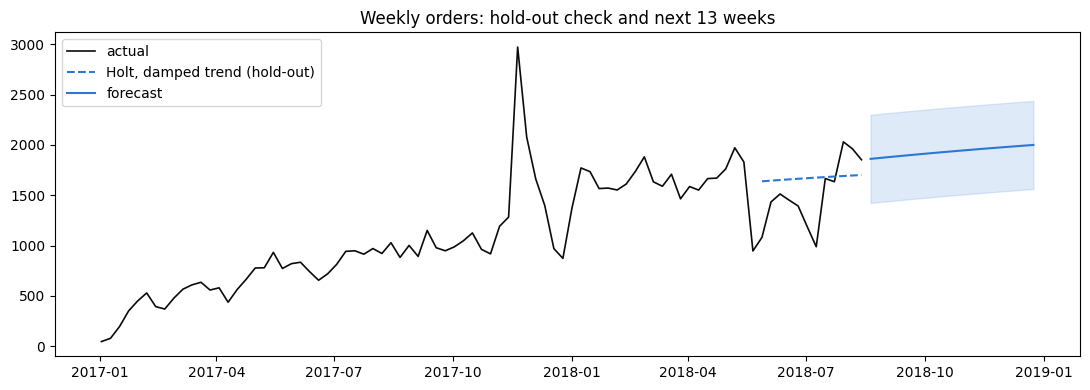

In [15]:
# Forecast every week from the end of the data to the end of 2018; "next quarter" = Q4 2018 (13 weeks from 1 Oct)
future = pd.date_range(y.index.max() + W, "2018-12-24", freq="W-MON")
FH = len(future)
q4 = (future >= "2018-10-01")
if best == "Holt, damped trend":
    fc = ExponentialSmoothing(y_adj, trend="add", damped_trend=True).fit().forecast(FH).values
elif best == "Linear trend":
    fc = np.polyval(np.polyfit(t, y_adj.values, 1), np.arange(len(y_adj), len(y_adj) + FH))
elif best == "Mean of last 8 weeks":
    fc = np.repeat(y_adj.iloc[-8:].mean(), FH)
else:
    fc = np.repeat(y_adj.iloc[-1], FH)
rmse = np.sqrt(np.mean((test.values - preds[best]) ** 2))
band = 1.28 * rmse                      # ~80% band, from the hold-out error
bf18 = pd.Timestamp("2018-11-19")       # Black Friday 2018 = 23 Nov
fc_bf = np.where(future == bf18, fc * bf_uplift, fc)

fcst = pd.concat([
    pd.DataFrame({"week": y.index, "actual": y.values,
                  "split": np.where(y.index >= test.index[0], "Hold-out", "Training")}),
    pd.DataFrame({"week": future, "forecast": fc, "forecast_bf": fc_bf, "low": fc - band, "high": fc + band, "split": "Forecast"}),
], ignore_index=True)
fcst.loc[fcst.split == "Hold-out", "holdout_pred"] = preds[best]
fcst.round(1).to_csv(OUT / "forecast_weekly.csv", index=False)

mape = float(models.set_index("model").loc[best, "mape"])
kpi("forecast_mape", round(mape, 4), f"Hold-out error (MAPE, last {H} weeks), {best}")
kpi("forecast_quarter", int(round(fc[q4].sum(), -1)), "Forecast orders, Q4 2018 (13 weeks), no Black Friday effect")
kpi("forecast_quarter_bf", int(round(fc_bf[q4].sum(), -1)), "Forecast orders, Q4 2018, with the 2017 Black Friday uplift")
kpi("forecast_quarter_low", int(round((fc[q4] - band).sum(), -1)), "Q4 2018 forecast, low end of the 80% band")
kpi("forecast_quarter_high", int(round((fc[q4] + band).sum(), -1)), "Q4 2018 forecast, high end of the 80% band")
kpi("forecast_week", int(round(fc.mean())), "Forecast average orders per week")
kpi("q4_2017_orders", int(y[(y.index >= "2017-10-02") & (y.index < "2018-01-01")].sum()), "Actual orders, Q4 2017 (13 weeks from 2 Oct)")
kpi("forecast_q4_growth", round(KPI["forecast_quarter"][0] / KPI["q4_2017_orders"][0] - 1, 4), "Q4 2018 forecast vs Q4 2017 actual")
kpi("bf_uplift", round(float(bf_uplift), 2), "Black Friday 2017 week vs a normal week")
kpi("forecast_naive_mape", round(float(models.set_index("model").loc["Naive (last week)", "mape"]), 4), "Hold-out MAPE of the naive forecast")
print({k: KPI[k][0] for k in ["forecast_mape", "forecast_quarter", "forecast_quarter_bf", "forecast_quarter_low",
                              "forecast_quarter_high", "forecast_week", "q4_2017_orders"]})

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y.index, y.values, color="#0B0B0B", lw=1.2, label="actual")
ax.plot(test.index, preds[best], color="#2A78D6", ls="--", label=f"{best} (hold-out)")
ax.plot(future, fc, color="#2A78D6", label="forecast")
ax.fill_between(future, fc - band, fc + band, color="#2A78D6", alpha=0.15)
ax.set_title("Weekly orders: hold-out check and next 13 weeks"); ax.legend(); plt.tight_layout(); plt.show()

## 6 · Recommendations, sized
1. **Cut lateness, starting with the big, poorly rated sellers.** Size: 1-2 star reviews avoided if half of the
   late orders had the on-time review profile.
2. **Win back one-time buyers.** Size: extra orders and GMV per year for each extra point of 180-day repurchase.
3. **Use high-repurchase categories as entry points.** Size: repurchase rate of the best categories vs average.

In [16]:
low_total = int((d.review_score <= 2).sum())
low_from_late = int(((d.review_score <= 2) & d.is_late).sum())
kpi("low_from_late_share", round(low_from_late / low_total, 4), "Share of all 1-2 star reviews that follow a late delivery")
all_late = int(d.is_late.sum())
avoided_half = 0.5 * all_late * (KPI["low_late"][0] - KPI["low_on_time"][0])   # halve lateness
fix_late_rate = seller_orders[seller_orders.seller_id.isin(set(fix.seller_id))].is_late.mean()
print(f"late orders = {all_late / len(d):.1%} of orders but {low_from_late / low_total:.1%} of 1-2 star reviews")
print(f"halving lateness avoids ~{avoided_half:,.0f} 1-2 star reviews ({avoided_half / low_total:.1%} of them)")
print(f"late rate at the 'fix first' sellers: {fix_late_rate:.1%} vs {all_late / len(d):.1%} overall")
kpi("fix_late_rate", round(float(fix_late_rate), 4), "Late rate of the big, poorly rated sellers")

fpd = pd.to_datetime(cust.first_purchase_date)
new_cust_12m = int(((fpd >= "2017-08-01") & (fpd < "2018-08-01")).sum())   # new customers over the last 12 months
gain_orders = new_cust_12m * 0.01
gain_gmv = gain_orders * KPI["aov"][0]

avg_rep = first.repurchase.mean()
top3 = cat_rep.head(3)

recs = pd.DataFrame([
    {"rank": 1, "action": "Cut lateness, starting with the big, poorly rated sellers",
     "evidence": f"Late orders are {KPI['late_share'][0]:.0%} of orders but {KPI['low_from_late_share'][0]:.0%} of all 1-2 star reviews. {len(fix)} top-10% sellers rate below 3.8 (late rate {fix_late_rate:.0%}).",
     "size": f"Halving lateness = ~{avoided_half:,.0f} fewer 1-2 star reviews ({avoided_half / low_total:.0%} of them)"},
    {"rank": 2, "action": "Win back one-time buyers with a second-order offer",
     "evidence": f"{KPI['one_time_share'][0]:.0%} of customers ordered once; only {avg_rep:.1%} reorder within 180 days.",
     "size": f"+1 pt of repurchase = ~{gain_orders:,.0f} extra orders and ~BRL {gain_gmv/1000:,.0f}k GMV per year ({new_cust_12m:,} new customers/yr)"},
    {"rank": 3, "action": "Acquire through the categories that bring customers back",
     "evidence": f"Best first-order categories: {', '.join(top3.category)} ({top3.repurchase_rate.min():.1%}-{top3.repurchase_rate.max():.1%} vs {avg_rep:.1%} average).",
     "size": f"Up to x{top3.repurchase_rate.max()/avg_rep:.1f} the average repurchase rate per customer acquired"},
])
pd.set_option("display.max_colwidth", 200)
print(recs.to_string(index=False))
recs.to_csv(OUT / "recommendations.csv", index=False)
kpi("rec1_avoided_low_reviews", int(round(avoided_half, -1)), "1-2 star reviews avoided by halving late deliveries")
kpi("rec1_avoided_share", round(avoided_half / low_total, 4), "Share of all 1-2 star reviews avoided by halving late deliveries")
kpi("rec3_top_rate", round(float(top3.repurchase_rate.max()), 4), "Best first-order category repurchase rate (180 days)")
kpi("rec2_orders_per_pt", int(round(gain_orders)), "Extra orders per year per +1 pt of repurchase")
kpi("rec2_gmv_per_pt", int(round(gain_gmv)), "Extra GMV (BRL) per year per +1 pt of repurchase")

late orders = 6.7% of orders but 32.8% of 1-2 star reviews
halving lateness avoids ~1,627 1-2 star reviews (14.0% of them)
late rate at the 'fix first' sellers: 9.6% vs 6.7% overall
 rank                                                    action                                                                                                         evidence                                                                                         size
    1 Cut lateness, starting with the big, poorly rated sellers Late orders are 7% of orders but 33% of all 1-2 star reviews. 32 top-10% sellers rate below 3.8 (late rate 10%).                               Halving lateness = ~1,627 fewer 1-2 star reviews (14% of them)
    2        Win back one-time buyers with a second-order offer                                                97% of customers ordered once; only 2.0% reorder within 180 days. +1 pt of repurchase = ~707 extra orders and ~BRL 113k GMV per year (70,688 new customers/yr)
    3  A

113483

In [17]:
kpis = pd.DataFrame([{"key": k, "value": v, "label": l} for k, (v, l) in KPI.items()])
kpis.to_csv(OUT / "kpis.csv", index=False)
print(kpis.to_string(index=False))

                     key        value                                                                        label
            valid_orders 9.148400e+04                                            Valid orders, Jan 2017 - Jul 2018
               gmv_total 1.468673e+07                                               GMV (BRL), Jan 2017 - Jul 2018
          gmv_growth_ytd 1.607600e+00                                      GMV growth Jan-Jul 2018 vs Jan-Jul 2017
       orders_growth_ytd 1.575700e+00                                   Orders growth Jan-Jul 2018 vs Jan-Jul 2017
               customers 8.849400e+04                       Real customers (customer_unique_id) with a valid order
             repeat_rate 3.040000e-02                 Share of customers with 2+ valid orders, Jan 2017 - Jul 2018
new_customer_order_share 9.672000e-01                            Share of orders that are a customer's first order
            retention_m1 4.800000e-03                          Average month-1 r